# Task B: Inheritance

You have been given a ready‑made binary classification pipeline. The attached baseline reports `ROC‑AUC ≈ 0.97` on its validation set.

Each row corresponds to an event involving a certain entity at the time specified by event_time. In production, the model is applied to later events. Among the future data, there are both known entities and groups, as well as those that have not been observed before.

The numerical features f_00–f_23 were obtained using the existing feature pipeline. Its documentation is incomplete, so the correctness of individual features and the original validation protocol cannot be guaranteed.

Your goal is to achieve the highest possible score on the hidden future period. You are allowed to change:
* the validation, 
* the set of features, 
* preprocessing, 
* the model, 
* the training method.

## files:
* `train.csv             —` features and target;
* `test.csv              —` a later period without target;
* `starter.py            —` the original baseline;
* `sample_submission.csv —` a sample submission;
* `requirements.txt      —` minimal environment.

## main columns:
* `row_id —` row identifier;
* `event_time —` event time in arbitrary seconds;
* `entity_id, group_id —` recurring categorical identifiers;
* `cat_00–cat_04 —` categorical features;
* `f_00–f_23 —` anonymous numerical features;
* `target —` binary target variable, available only in `train`.

**NB!:** Rows in `train.csv` are shuffled. Rows in `test.csv` belong to a period subsequent to `train`.

## submission format
You must submit only a CSV file:

row_id,prediction

10000001,0.031

10000002,0.772

## requirements:

1) exactly one row for each `row_id` from `test.csv`;
2) columns must be named `row_id` and `prediction`;
3) prediction must be a finite number between `0` and `1`;
4) extra, missing, or duplicate `row_id` values are not allowed;
5) no text answers or code need to be submitted.

## metrics
The hidden test is divided into three consecutive time blocks. Let `A1`, `A2`, `A3` denote the `ROC‑AUC` on these blocks.

A cold‑start subset is defined separately: rows where `entity_id` or `group_id` did not appear in train. Let `Acold` denote the `ROC‑AUC` on this subset.

### robust quality $R$ is calculated first:

$$
R \;=\; 0.50 \cdot mean(A_1, A_2, A_3) \;+\; 0.25 \cdot A_{cold} \;+\; 0.25 \cdot min(A_1, A_2, A_3, A_{cold})
$$

### final score:

$$
Score \;=\; 100 \;\cdot\; clip\left(\,\frac{(R - 0.55)}{0.20}, \, 0, \, 1\right)
$$

### benchmarks:
* `0 points  :` R ≤ 0.55;
* `50 points :` R = 0.65;
* `75 points :` R = 0.70;
* `100 points:` R ≥ 0.75.

The higher the score, the better. The best submission counts.

In [776]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
#from datetime import timedelta


from catboost import CatBoostClassifier
from sklearn.metrics import roc_auc_score, roc_curve, precision_recall_curve
from sklearn.model_selection import train_test_split

# Deliberately naive starter baseline

## read datasets

In [777]:
train = pd.read_csv("../data/data_B/train.csv")
train.info()

<class 'pandas.DataFrame'>
RangeIndex: 140035 entries, 0 to 140034
Data columns (total 34 columns):
 #   Column      Non-Null Count   Dtype  
---  ------      --------------   -----  
 0   row_id      140035 non-null  int64  
 1   event_time  140035 non-null  int64  
 2   entity_id   140035 non-null  int64  
 3   group_id    140035 non-null  int64  
 4   cat_00      140035 non-null  int64  
 5   cat_01      140035 non-null  int64  
 6   cat_02      140035 non-null  int64  
 7   cat_03      140035 non-null  int64  
 8   cat_04      140035 non-null  int64  
 9   f_00        140035 non-null  float64
 10  f_01        140035 non-null  float64
 11  f_02        140035 non-null  float64
 12  f_03        140035 non-null  float64
 13  f_04        140035 non-null  float64
 14  f_05        140035 non-null  float64
 15  f_06        140035 non-null  float64
 16  f_07        140035 non-null  float64
 17  f_08        140035 non-null  float64
 18  f_09        140035 non-null  float64
 19  f_10        1

In [778]:
test = pd.read_csv("../data/data_B/test.csv")
test.info()

<class 'pandas.DataFrame'>
RangeIndex: 63270 entries, 0 to 63269
Data columns (total 33 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   row_id      63270 non-null  int64  
 1   event_time  63270 non-null  int64  
 2   entity_id   63270 non-null  int64  
 3   group_id    63270 non-null  int64  
 4   cat_00      63270 non-null  int64  
 5   cat_01      63270 non-null  int64  
 6   cat_02      63270 non-null  int64  
 7   cat_03      63270 non-null  int64  
 8   cat_04      63270 non-null  int64  
 9   f_00        63270 non-null  float64
 10  f_01        63270 non-null  float64
 11  f_02        63270 non-null  float64
 12  f_03        63270 non-null  float64
 13  f_04        63270 non-null  float64
 14  f_05        63270 non-null  float64
 15  f_06        63270 non-null  float64
 16  f_07        63270 non-null  float64
 17  f_08        63270 non-null  float64
 18  f_09        63270 non-null  float64
 19  f_10        63270 non-null  float64


### look at the target statistics

In [779]:
train.target.value_counts(dropna=False, normalize=True) * 100

target
0    97.444924
1     2.555076
Name: proportion, dtype: float64

### check if row_id is unique

In [780]:
train.row_id.value_counts(dropna=False)

row_id
10082466    1
10022591    1
10133054    1
10092682    1
10070012    1
           ..
10033930    1
10045529    1
10120962    1
10080876    1
10118087    1
Name: count, Length: 140035, dtype: int64

In [781]:
test.row_id.value_counts(dropna=False)

row_id
10140035    1
10140036    1
10140037    1
10140038    1
10140039    1
           ..
10203300    1
10203301    1
10203302    1
10203303    1
10203304    1
Name: count, Length: 63270, dtype: int64

### check if time separation is valid

In [782]:
train.event_time.max() < test.event_time.min()

np.True_

## select and detect fields type

In [783]:
features = [c for c in test.columns if c != "row_id"]
#features

In [784]:
cat_features = ["entity_id", "group_id"] + [c for c in features if c.startswith("cat_")]
cat_features

['entity_id', 'group_id', 'cat_00', 'cat_01', 'cat_02', 'cat_03', 'cat_04']

### changing categorical columns to string-type

In [785]:
for frame in (train, test):
    for col in cat_features:
        frame[col] = frame[col].astype(str)

train.info()

<class 'pandas.DataFrame'>
RangeIndex: 140035 entries, 0 to 140034
Data columns (total 34 columns):
 #   Column      Non-Null Count   Dtype  
---  ------      --------------   -----  
 0   row_id      140035 non-null  int64  
 1   event_time  140035 non-null  int64  
 2   entity_id   140035 non-null  str    
 3   group_id    140035 non-null  str    
 4   cat_00      140035 non-null  str    
 5   cat_01      140035 non-null  str    
 6   cat_02      140035 non-null  str    
 7   cat_03      140035 non-null  str    
 8   cat_04      140035 non-null  str    
 9   f_00        140035 non-null  float64
 10  f_01        140035 non-null  float64
 11  f_02        140035 non-null  float64
 12  f_03        140035 non-null  float64
 13  f_04        140035 non-null  float64
 14  f_05        140035 non-null  float64
 15  f_06        140035 non-null  float64
 16  f_07        140035 non-null  float64
 17  f_08        140035 non-null  float64
 18  f_09        140035 non-null  float64
 19  f_10        1

## random split of train indicies into cv_train and cv_valid groups
* we know true target values only for train-dataset, thus to estimate metrics on the new data we have to split it too;
* `NB!:` yet baseline uses random split, while not separating past and future data, which augments results on validation data by autocorrelation dependencies found in the training

In [786]:
train_idx, valid_idx = train_test_split(
    range(len(train)),
    test_size=0.25,
    random_state=42,
    stratify=train["target"],
)

## using CatBoost

In [787]:
baseline_model = CatBoostClassifier(
    iterations=140,
    depth=7,
    learning_rate=0.11,
    loss_function="Logloss",
    eval_metric="AUC",
    l2_leaf_reg=6,
    random_seed=42,
    verbose=False,
    allow_writing_files=False,
)

In [788]:
baseline_model.fit(
    train.loc[train_idx, features],
    train.loc[train_idx, "target"],
    cat_features=[features.index(c) for c in cat_features],
)

CatBoostClassifier(allow_writing_files=False, depth=7, eval_metric='AUC', iterations=140, l2_leaf_reg=6, learning_rate=0.11, loss_function='Logloss', random_seed=42, verbose=False)

In [789]:
valid_prediction = baseline_model.predict_proba(train.loc[valid_idx, features])[:, 1]

In [790]:

print(f"Random-split baseline ROC-AUC: {roc_auc_score(train.loc[valid_idx, 'target'], valid_prediction):.6f}")

Random-split baseline ROC-AUC: 0.970494


### retrain model on the whole train dataset

In [791]:

baseline_model.fit(
    train[features],
    train["target"],
    cat_features=[features.index(c) for c in cat_features],
)

CatBoostClassifier(allow_writing_files=False, depth=7, eval_metric='AUC', iterations=140, l2_leaf_reg=6, learning_rate=0.11, loss_function='Logloss', random_seed=42, verbose=False)

### save results for submission

In [792]:
test_prediction = baseline_model.predict_proba(test[features])[:, 1]

pd.DataFrame({"row_id": test["row_id"], "prediction": test_prediction}).to_csv(
                                       "../results/baseline_submission.csv", index=False)

print('FYI: baseline_submission.csv has been saved OK!')


FYI: baseline_submission.csv has been saved OK!


# Improving baseline model follows

## 1. Train validation with time separation
Actually, this should lower ROC-AUC score as short autocorrelations are no more affecting inference - but this is closer results to the real testing in the exam

In [793]:
split_idx = int(len(train) * 0.75)

tmp = train.sort_values('event_time')
cv_train = tmp.iloc[:split_idx].sample(frac=1, axis=0)
cv_valid = tmp.iloc[split_idx:]

In [794]:
baseline_model.fit(
    cv_train[features],
    cv_train["target"],
    cat_features=[features.index(c) for c in cat_features],
)

CatBoostClassifier(allow_writing_files=False, depth=7, eval_metric='AUC', iterations=140, l2_leaf_reg=6, learning_rate=0.11, loss_function='Logloss', random_seed=42, verbose=False)

In [795]:
comp_prc_df = pd.DataFrame()
comp_roc_df = pd.DataFrame(index=range(2000)) # the length of ROC points can differ!!
roc_score_dict = {}

In [796]:
valid_prediction = baseline_model.predict_proba(cv_valid[features])[:, 1]

precision, recall, thres = precision_recall_curve(cv_valid['target'], valid_prediction)
fpr, tpr, thres                       = roc_curve(cv_valid['target'], valid_prediction)

len(precision), len(recall), len(fpr), len(tpr)


(35010, 35010, 1042, 1042)

In [797]:
comp_prc_df['tspl_val_baseline'] = [ el for el in zip(recall, precision) ]

comp_roc_addon = pd.Series([ el for el in zip(fpr, tpr) ], name='tspl_val_baseline').to_frame()
comp_roc_df = pd.concat([comp_roc_df, comp_roc_addon], axis=1)

In [798]:
roc_score = roc_auc_score(cv_valid['target'], valid_prediction)
roc_score_dict['tspl_val_baseline'] = roc_score

print(f"Time-split baseline ROC-AUC: {roc_score:.6f}")

Time-split baseline ROC-AUC: 0.961627


## PreProc & EDA

In [799]:
train.info()

<class 'pandas.DataFrame'>
RangeIndex: 140035 entries, 0 to 140034
Data columns (total 34 columns):
 #   Column      Non-Null Count   Dtype  
---  ------      --------------   -----  
 0   row_id      140035 non-null  int64  
 1   event_time  140035 non-null  int64  
 2   entity_id   140035 non-null  str    
 3   group_id    140035 non-null  str    
 4   cat_00      140035 non-null  str    
 5   cat_01      140035 non-null  str    
 6   cat_02      140035 non-null  str    
 7   cat_03      140035 non-null  str    
 8   cat_04      140035 non-null  str    
 9   f_00        140035 non-null  float64
 10  f_01        140035 non-null  float64
 11  f_02        140035 non-null  float64
 12  f_03        140035 non-null  float64
 13  f_04        140035 non-null  float64
 14  f_05        140035 non-null  float64
 15  f_06        140035 non-null  float64
 16  f_07        140035 non-null  float64
 17  f_08        140035 non-null  float64
 18  f_09        140035 non-null  float64
 19  f_10        1

### Field: `event_time`

In [800]:
train.event_time.value_counts(dropna=False)

event_time
10427310    3
14987428    3
1879434     3
14738538    3
10660984    3
           ..
4116356     1
5506192     1
13622768    1
9403986     1
13351465    1
Name: count, Length: 139170, dtype: int64

In [801]:
timestep = 1

train['td'] = pd.to_datetime(train.event_time * timestep, unit='s')
test['td'] = pd.to_datetime(test.event_time   * timestep, unit='s')

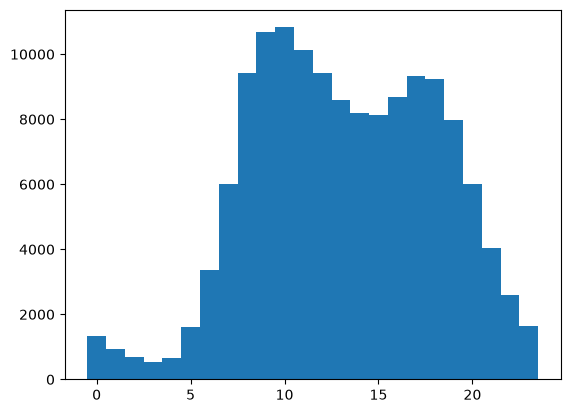

In [802]:
plt.hist(train.td.map(lambda x: x.hour), bins=[-0.5 + h for h in range(25)])
plt.show()

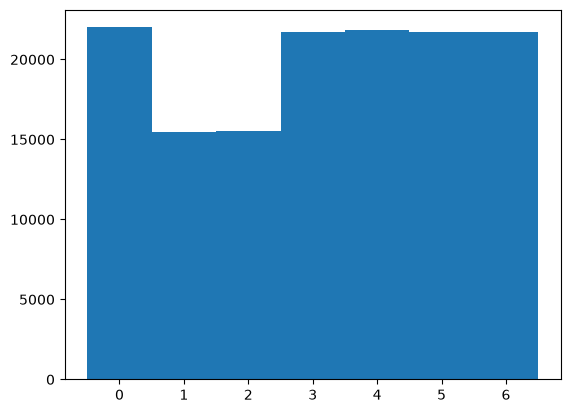

In [803]:
plt.hist(train.td.map(lambda x: x.day_of_week), bins=[-0.5 + h for h in range(8)])
plt.show()

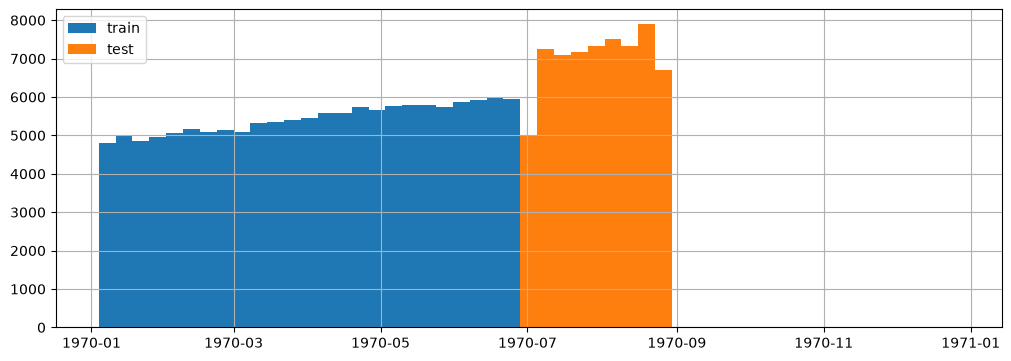

In [804]:
time_bins = pd.date_range(start="1970-01-01", end="1971-01-01", freq="W")

plt.figure(figsize=(10,3.5), layout='constrained')

plt.hist(train.td, bins=time_bins, label='train')
plt.hist(test.td, bins=time_bins, label='test')

#plt.xticks([pd.to_datetime(str(year) + '-01-01') for year in range(1970, 2026)], minor=True)
plt.grid(which='both')

plt.legend(loc='upper left')
plt.show()

In [805]:
train['day_of_week'] = train.td.map(lambda x: x.day_of_week).map(lambda x: 'weekend' if x in [1,2] else 'working')
train['hour_of_day'] = train.td.map(lambda x: 'h_' + str(x.hour))

test['day_of_week'] = test.td.map(lambda x: x.day_of_week).map(lambda x: 'weekend' if x in [1,2] else 'working')
test['hour_of_day'] = test.td.map(lambda x: 'h_' + str(x.hour))

In [806]:
features_seasonal = ['day_of_week','hour_of_day']

In [807]:
split_idx = int(len(train) * 0.75)

tmp = train.sort_values('event_time')
cv_train = tmp.iloc[:split_idx].sample(frac=1, axis=0)
cv_valid = tmp.iloc[split_idx:]

In [808]:
baseline_model.fit(
    cv_train[features + features_seasonal],
    cv_train["target"],
    cat_features=[(features + features_seasonal).index(c) for c in (cat_features + features_seasonal)],
)

CatBoostClassifier(allow_writing_files=False, depth=7, eval_metric='AUC', iterations=140, l2_leaf_reg=6, learning_rate=0.11, loss_function='Logloss', random_seed=42, verbose=False)

In [809]:
valid_prediction = baseline_model.predict_proba(cv_valid[features + features_seasonal])[:, 1]

precision, recall, thres = precision_recall_curve(cv_valid['target'], valid_prediction)
fpr, tpr, thres                       = roc_curve(cv_valid['target'], valid_prediction)

len(precision), len(recall), len(fpr), len(tpr)

(35010, 35010, 1024, 1024)

In [810]:

comp_prc_df['tspl_val_seasonal'] = [ el for el in zip(recall, precision) ]

comp_roc_addon = pd.Series([ el for el in zip(fpr, tpr) ], name='tspl_val_seasonal').to_frame()
comp_roc_df = pd.concat([comp_roc_df, comp_roc_addon], axis=1)

In [811]:
roc_score = roc_auc_score(cv_valid['target'], valid_prediction)
roc_score_dict['tspl_val_seasonal'] = roc_score

print(f"Time-split with seasonal ROC-AUC: {roc_score:.6f}")

Time-split with seasonal ROC-AUC: 0.965935


### Field: `entity_id`

In [812]:
train.entity_id.value_counts(dropna=False)

entity_id
102643    327
102910    316
100889    315
100810    305
100475    300
         ... 
101211      3
102250      3
101276      3
101397      3
100846      1
Name: count, Length: 2600, dtype: int64

#### check if there are new `entity_ids` in test

In [813]:
new_entity_ids = []

old_entity_ids = set(train.entity_id.to_list())

for eid in test.entity_id.unique():
    if eid not in old_entity_ids:
        new_entity_ids.append(eid)

print('FYI: there are', len(new_entity_ids), 'new unique entity_ids out of', len(test.entity_id.unique()), 
      'in test data' )

FYI: there are 498 new unique entity_ids out of 3094 in test data


#### check if time split of train with validation also gives new `entity_ids`

In [814]:
new_entity_ids = []

old_entity_ids = set(cv_train.entity_id.to_list())

for eid in cv_valid.entity_id.unique():
    if eid not in old_entity_ids:
        new_entity_ids.append(eid)

print('FYI: there are', len(new_entity_ids), 'new unique entity_ids out of', len(cv_valid.entity_id.unique()), 
      'in cv_validation data split by time' )

FYI: there are 0 new unique entity_ids out of 2581 in cv_validation data split by time


### Field: `group_id` 

In [815]:
train.group_id.value_counts(dropna=False)

group_id
50316    474
50367    458
50234    456
50410    456
50241    455
        ... 
50531    138
50211    137
50218    132
50448    122
50119    120
Name: count, Length: 520, dtype: int64

#### check if an entity can be in one group only
* `NB!:` Actually, almost never! Only for one entity_id!
* one could have guessed about group renaming, but not up to 40 times!
* thus, `entity` and `groups` do not have much of mnemonical semantics - at least it does not look to be the groups of entities

In [816]:
train.groupby('entity_id').agg({'group_id':'nunique'}).sort_values('group_id')

,group_id
entity_id,
100846,1
102292,2
101850,2
101211,2
100455,2
...,...
101108,33
100889,35
100541,36


#### check if there are new `group_ids` in test

In [817]:
new_group_ids = []

old_group_ids = set(train.group_id.to_list())

for eid in test.group_id.unique():
    if eid not in old_group_ids:
        new_group_ids.append(eid)

print('FYI: there are', len(new_group_ids), 'new unique group_ids out of', len(test.group_id.unique()), 
      'in test data' )

FYI: there are 80 new unique group_ids out of 600 in test data


#### check if time split of train with validation also gives new `group_ids`

In [818]:
new_group_ids = []

old_group_ids = set(cv_train.group_id.to_list())

for eid in cv_valid.group_id.unique():
    if eid not in old_group_ids:
        new_group_ids.append(eid)

print('FYI: there are', len(new_group_ids), 'new unique group_ids out of', len(cv_valid.group_id.unique()), 
      'in cv_validation data split by time' )

FYI: there are 0 new unique group_ids out of 520 in cv_validation data split by time


# Cold start problem
* there are about 15% of new entities and groups in test dataset, thus we need a separate model for them

## model without seasonality

In [819]:
no_id_features = [el for el in features if not el.endswith('_id')]
no_id_cat_features = [el for el in cat_features if not el.endswith('_id')]

In [820]:
baseline_model.fit(
    cv_train[no_id_features],
    cv_train["target"],
    cat_features=[no_id_features.index(c) for c in no_id_cat_features],
)

CatBoostClassifier(allow_writing_files=False, depth=7, eval_metric='AUC', iterations=140, l2_leaf_reg=6, learning_rate=0.11, loss_function='Logloss', random_seed=42, verbose=False)

In [821]:
valid_prediction = baseline_model.predict_proba(cv_valid[no_id_features])[:, 1]

precision, recall, thres = precision_recall_curve(cv_valid['target'], valid_prediction)
fpr, tpr, thres                       = roc_curve(cv_valid['target'], valid_prediction)

len(precision), len(recall), len(fpr), len(tpr)

(35010, 35010, 1038, 1038)

In [822]:
comp_prc_df['tspl_val_baseline_no_id'] = [ el for el in zip(recall, precision) ]

comp_roc_addon = pd.Series([ el for el in zip(fpr, tpr) ], name='tspl_val_baseline_no_id').to_frame()
comp_roc_df = pd.concat([comp_roc_df, comp_roc_addon], axis=1)

In [823]:
roc_score = roc_auc_score(cv_valid['target'], valid_prediction)
roc_score_dict['tspl_val_baseline_no_id'] = roc_score

print(f"Time-split baseline cold-start ROC-AUC: {roc_score:.6f}")

Time-split baseline cold-start ROC-AUC: 0.962087


## model with seasonality

In [824]:
baseline_model.fit(
    cv_train[no_id_features + features_seasonal],
    cv_train["target"],
    cat_features=[(no_id_features + features_seasonal).index(c) for c in (no_id_cat_features + features_seasonal)],
)

CatBoostClassifier(allow_writing_files=False, depth=7, eval_metric='AUC', iterations=140, l2_leaf_reg=6, learning_rate=0.11, loss_function='Logloss', random_seed=42, verbose=False)

In [825]:
valid_prediction = baseline_model.predict_proba(cv_valid[no_id_features + features_seasonal])[:, 1]

precision, recall, thres = precision_recall_curve(cv_valid['target'], valid_prediction)
fpr, tpr, thres                       = roc_curve(cv_valid['target'], valid_prediction)

len(precision), len(recall), len(fpr), len(tpr)

(35010, 35010, 1056, 1056)

In [826]:
comp_prc_df['tspl_val_seasonal_no_id'] = [ el for el in zip(recall, precision) ]

comp_roc_addon = pd.Series([ el for el in zip(fpr, tpr) ], name='tspl_val_seasonal_no_id').to_frame()
comp_roc_df = pd.concat([comp_roc_df, comp_roc_addon], axis=1)

In [827]:
roc_score = roc_auc_score(cv_valid['target'], valid_prediction)
roc_score_dict['tspl_val_seasonal_no_id'] = roc_score

print(f"Time-split seasonal cold-start ROC-AUC: {roc_score:.6f}")

Time-split seasonal cold-start ROC-AUC: 0.962304


# Compare different models on Presision Recall and ROC-AUC curves

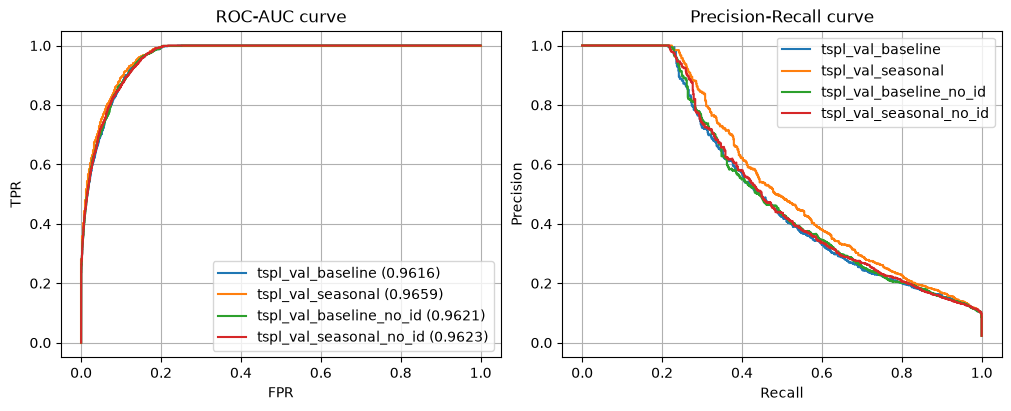

In [828]:
fig, (ax1, ax2) = plt.subplots(1,2, figsize=(10, 4), layout='constrained')

for mdl in comp_roc_df.columns.to_list():

    ax1.plot([comp_roc_df[mdl].dropna().iloc[i][0] for i in range(len(comp_roc_df[mdl].dropna()))], 
             [comp_roc_df[mdl].dropna().iloc[i][1] for i in range(len(comp_roc_df[mdl].dropna()))], 
             label=mdl + ' (' + str(round(roc_score_dict[mdl],4)) + ')')
    ax2.plot([comp_prc_df[mdl].iloc[i][0] for i in range(len(comp_prc_df))], 
             [comp_prc_df[mdl].iloc[i][1] for i in range(len(comp_prc_df))], label=mdl)

ax1.set_xlabel('FPR')
ax1.set_ylabel('TPR')
ax2.set_xlabel('Recall')
ax2.set_ylabel('Precision')

ax1.set_xlim(-0.05,1.05)
ax1.set_ylim(-0.05,1.05)
ax2.set_xlim(-0.05,1.05)
ax2.set_ylim(-0.05,1.05)
ax1.grid()
ax2.grid()
ax1.set_title('ROC-AUC curve')
ax2.set_title('Precision-Recall curve')

ax1.legend()
ax2.legend()    

plt.show()